In [2]:
import sys
import os
import dask
import dask.dataframe as dd
import pandas as pd
import matplotlib.pyplot as plt

# import utils.py from two levels up
current_dir = os.getcwd()
parent_dir = os.path.abspath(os.path.join(current_dir, '..'))
sys.path.append(parent_dir)
from utils import print_stats_and_graphs

In [ ]:
mc_med_path = '~/mc-med-1.0.0/data/'

## Visits
Contains high-level visit information (e.g., patient age, sex, arrival method, chief complaint, disposition, timing of events).

In [5]:
visits = dd.read_csv(mc_med_path + 'visits.csv', assume_missing=True)

# Preprocess: Convert MRN, CSN and Visit_no to int
visits['MRN'] = visits['MRN'].astype('Int64')
visits['CSN'] = visits['CSN'].astype('Int64')
visits['Visit_no'] = visits['Visit_no'].astype('Int64')

# Report: Number of unique patients
unique_patients = visits['MRN'].nunique().compute()
print(f"Number of unique patients: {unique_patients}")
# Report: Number of unique visits
unique_visits = visits['CSN'].nunique().compute()
print(f"Number of unique visits: {unique_visits}")
# Report: Median number of unique visits per patient
median_visits_per_patient = visits.groupby('MRN')['CSN'].nunique().median().compute()
print(f"Median number of unique visits per patient: {median_visits_per_patient}")

Number of unique patients: 70545
Number of unique visits: 118385
Median number of unique visits per patient: 1.0


In [ ]:
# print_stats_and_graphs(visits, 'Age', bins=20, save_plot=True)
# print_stats_and_graphs(visits, 'Gender', save_plot=True)
# print_stats_and_graphs(visits, 'Race', save_plot=True)
# print_stats_and_graphs(visits, 'Means_of_arrival', save_plot=True)
# print_stats_and_graphs(visits, 'ED_dispo', save_plot=True)
# print_stats_and_graphs(visits, 'ED_LOS', bins=100, save_plot=True)
# print_stats_and_graphs(visits, 'Hosp_LOS', bins=100, save_plot=True)
# print_stats_and_graphs(visits, 'DC_dispo', save_plot=True, categorical_threshold=40)
# print_stats_and_graphs(visits, 'Dx_ICD10', save_plot=True, categorical_threshold=40)

Analyzing column 'Dx_ICD10':
  Column 'Dx_ICD10' has 6565 unique values, exceeding the categorical threshold.
  Skipping detailed analysis and plotting for high-cardinality non-numeric column.


{}

In [13]:
visits.head()

,MRN,CSN,Visit_no,Visits,Age,Gender,Race,Ethnicity,Means_of_arrival,Triage_Temp,...,Payor_class,Admit_service,Dx_ICD9,Dx_ICD10,Dx_name,Arrival_time,Roomed_time,Dispo_time,Admit_time,Departure_time
0,98880961,98874959,1,1.0,82.0,F,White,Non-Hispanic/Non-Latino,EMS,36.2,...,Medicare,Medicine,873.20,S01.21XA,"Laceration of nose, initial encounter",2283-03-02T07:36:59Z,2283-03-02T07:36:59Z,2283-03-02T12:29:59Z,2283-03-02T12:29:59Z,2283-03-02T13:44:59Z
1,99121566,99354408,1,2.0,59.0,F,Other,Non-Hispanic/Non-Latino,EMS,36.8,...,<NA>,Emergency Medicine,780.97,R41.82,"Altered mental status, unspecified altered men...",2239-08-22T01:13:51Z,2239-08-22T01:16:51Z,2239-08-22T07:20:51Z,2239-08-22T07:20:51Z,2239-08-22T10:45:51Z
2,99121566,99121037,2,2.0,63.0,F,Other,Non-Hispanic/Non-Latino,EMS,37.2,...,<NA>,Critical Care,"038.9, 785.52, 995.92","A41.9, R65.21",Septic shock (CMS-HCC),2240-03-11T03:06:51Z,2240-03-11T03:43:51Z,2240-03-11T08:31:51Z,2240-03-11T08:31:51Z,2240-03-11T13:37:51Z
3,99608739,99327434,1,2.0,90.0,F,White,Non-Hispanic/Non-Latino,Self,NaN,...,Medicare,<NA>,729.81,M79.89,Leg swelling,2296-08-31T16:43:05Z,2296-08-31T17:56:05Z,2296-08-31T20:56:05Z,<NA>,2296-08-31T21:06:05Z
4,99608739,99502864,2,2.0,89.0,F,White,Non-Hispanic/Non-Latino,Self,36.4,...,Medicare,<NA>,788.20,R33.9,Urinary retention,2297-06-07T05:08:05Z,2297-06-07T05:59:05Z,2297-06-07T08:55:05Z,<NA>,2297-06-07T09:35:05Z


## Labs
Contains laboratory test results (e.g., blood tests, urine tests, cultures).

In [97]:
labs = dd.read_csv(mc_med_path + 'labs.csv', assume_missing=True, dtype={'Component_value': 'string'})
# preprocess: Convert CSN to int
labs['CSN'] = labs['CSN'].astype('Int64')


In [ ]:
labs_grouped = labs.groupby('CSN')

unique_csns = labs['CSN'].nunique()
median_number_of_labs = labs_grouped.size()

unique_csns_computed, number_of_labs_computed = dask.compute(unique_csns, median_number_of_labs)

# Report: Number of unique CSNs
print(f"Number of unique CSNs: {unique_csns_computed}")
# Report: Median number of labs per CSN
print(f"Median number of labs per CSN: {number_of_labs_computed.median()}")
print(f"Q1 number of labs per CSN: {number_of_labs_computed.quantile(0.25)}")
print(f"Q3 number of labs per CSN: {number_of_labs_computed.quantile(0.75)}")

Number of unique CSNs: 102753


AttributeError: 'float' object has no attribute 'compute'

## Lab Frequency
Key insight 1: most labs are done once per visit! so we can't infer much from progression of a particular lab over time; we need to rely on the relations between labs to infer disease progression.

Key insight 2: there are a median of five unique result times per CSN. that means we don't have many repeated measures per patient. 

In [ ]:
# Get the value counts for the 'Display_name' column
# This counts the occurrences of each unique lab name
lab_counts = labs['Component_name'].value_counts()

# Compute the results (Dask operations are lazy, .compute() triggers execution)
lab_counts_computed = lab_counts.compute()

# Sort the results in descending order to get the most frequent labs first
most_frequent_labs = lab_counts_computed.sort_values(ascending=False)

# Report: Print the top 10 most frequent labs
print("Top 10 Most Frequently Measured Labs:")
print(most_frequent_labs.head(200).to_string())

Top 10 Most Frequently Measured Labs:
Component_name
SODIUM                            111199
BLOOD UREA NITROGEN (BUN)         110789
GLUCOSE                           110763
POTASSIUM                         106881
CALCIUM                           106721
CREATININE                        106392
CO2                               106380
CHLORIDE                          106376
ANION GAP                         106344
EGFR REFIT WITHOUT RACE (2021)    105192
Name: count, dtype: int64[pyarrow]


In [65]:
# Filter the dataframe to only include rows where Component_name is 'SODIUM'
sodium_results_df = labs[labs['Component_name'] == 'SODIUM']
    
# Group the filtered data by CSN (visit identifier) and count the occurrences
# This will give us the number of times 'SODIUM' was measured in each visit
sodium_counts_per_visit = sodium_results_df.groupby('CSN').size()

# Compute the results
sodium_counts_per_visit_computed = sodium_counts_per_visit.compute()

# Count how many visits have more than one 'SODIUM' measurement
visits_with_multiple_sodium = (sodium_counts_per_visit_computed > 1).sum()

# Get the total number of visits that had at least one SODIUM measurement
total_visits_with_sodium = len(sodium_counts_per_visit_computed)

# Calculate the median number of SODIUM measurements per visit
# We use .median() on the pandas Series obtained after computing
median_sodium_per_visit = sodium_counts_per_visit_computed.median()


print(f"Total visits with at least one SODIUM measurement: {total_visits_with_sodium}")
print(f"Visits with more than one SODIUM measurement: {visits_with_multiple_sodium}")
print(f"Median number of SODIUM measurements per visit (for visits with at least one SODIUM measurement): {median_sodium_per_visit}")

Total visits with at least one SODIUM measurement: 94687
Visits with more than one SODIUM measurement: 11040
Median number of SODIUM measurements per visit (for visits with at least one SODIUM measurement): 1.0


In [ ]:
# Convert Result_time to datetime
labs['Result_time'] = dd.to_datetime(labs['Result_time'], errors='coerce')
print("Converting Result_time to datetime...")
# drop na
labs_df = labs.dropna(subset=['Result_time']).compute()

# Report: Number of unique result_time per CSN 
unique_result_times = labs_df.groupby('CSN')['Result_time'].nunique()
# Report: Median number of unique result_time
median_result_times = unique_result_times.median()
print(f"Median number of unique result_time per CSN: {median_result_times}")
# Report: Q1 number of unique result_time
print(f"Q1 number of unique result_time per CSN: {unique_result_times.quantile(0.25)}")
# Report: Q3 number of unique result_time
print(f"Q3 number of unique result_time per CSN: {unique_result_times.quantile(0.75)}")
print("Minimum number of unique result_time per CSN: ", unique_result_times.min()) # 1
print("Maximum number of unique result_time per CSN: ", unique_result_times.max()) # 504
print("90th percentile number of unique result_time per CSN: ", unique_result_times.quantile(0.90)) # 2

Converting Result_time to datetime...
Median number of unique result_time per CSN: 5.0
Q1 number of unique result_time per CSN: 4.0
Q3 number of unique result_time per CSN: 7.0


In [ ]:
# Sort the dataframe by CSN and Result_time
# While sorting is useful for diff(), it might not be strictly necessary for the
# final groupby().agg() if you only need the overall sum/count per CSN.
# However, it's needed for the diff calculation, so keep it here.
labs_df = labs_df.sort_values(by=['CSN', 'Result_time'])
print("Sorting the labs dataframe by CSN and Result_time...")

# for each CSN, drop duplicates where Result_time is the same
labs_df = labs_df.drop_duplicates(subset=['CSN', 'Result_time'])

# Group by CSN and calculate the time difference between consecutive measurements
# Use transform to apply diff() within each group
labs_df['Time_diff'] = labs_df.groupby('CSN')['Result_time'].transform(lambda x: x.diff()).dt.total_seconds() / 3600  # convert to hours
print("Calculating time differences...")

# Drop rows where Time_diff is NaN (the first entry for each CSN)
labs_with_diff = labs_df.dropna(subset=['Time_diff'])

# Now, calculate the median 'Time_diff' for each CSN 
average_time_diff_per_csn = labs_with_diff.groupby('CSN')['Time_diff'].agg(['mean', 'median', 'std']).reset_index()

# Report: Compute the average of the median, std and mean time differences
average_time_diff = average_time_diff_per_csn[['mean', 'median', 'std']].mean()
print(f"Average of the median, std and mean time differences: {average_time_diff.to_string()}")

Converting Result_time to datetime...
Sorting the labs dataframe by CSN and Result_time...
Calculating time differences...
Average of the median, std and mean time differences: mean      0.628347
median    0.410761
std       0.693024


,CSN,Order_time,Result_time,Display_name,Abnormal,Component_name,Component_result,Component_value,Component_units,Component_abnormal,Component_nml_low,Component_nml_high,Time_diff
404494,98816159,2203-08-16T20:49:08Z,2203-08-16 22:58:08+00:00,RAPID COVID (aka Rapid Coronavirus 2019 (SARS-...,<NA>,SARS-COV-2 RNA,Not Detected,1,<NA>,Normal,NaN,NaN,0.166667
404530,98816159,2203-08-16T23:01:08Z,2203-08-17 00:11:08+00:00,Lipase,Normal,LIPASE,26,26,U/L,Normal,13.0,60.000,1.216667
404496,98816159,2203-08-16T20:53:08Z,2203-08-17 00:18:08+00:00,"Metabolic Panel, Comprehensive",Abnormal,CHLORIDE,95,95,mmol/L,Abnormal Low,98.0,107.000,0.116667
404531,98816159,2203-08-16T23:18:08Z,2203-08-17 00:55:08+00:00,Troponin I,Normal,TROPONIN I,<0.017,<.017,ng/mL,Normal,NaN,0.055,0.616667
404495,98816159,2203-08-16T20:53:08Z,2203-08-17 01:56:08+00:00,"Urinalysis, UTI Screen for Culture",Abnormal,LEUKOCYTE ESTERASE: URINE (UA),Negative,34,<NA>,Normal,NaN,NaN,1.016667
174541,98816167,2214-07-12T15:41:32Z,2214-07-12 19:22:32+00:00,CBC,Abnormal,WHITE BLOOD CELLS (WBC),11.7,11.7,K/uL,Abnormal High,4.0,11.000,1.783333
174551,98816167,2214-07-12T15:41:32Z,2214-07-12 19:49:32+00:00,"Urinalysis, UTI Screen for Culture",Abnormal,BLOOD: URINE (UA),Negative,34,<NA>,Normal,NaN,NaN,0.450000
174542,98816167,2214-07-12T15:41:32Z,2214-07-12 19:55:32+00:00,Lipase,Normal,LIPASE,31,31,U/L,Normal,13.0,60.000,0.100000
174575,98816167,2214-07-12T15:45:32Z,2214-07-12 20:44:32+00:00,COVID (aka 2019 Novel Coronavirus (SARS-CoV-2)...,<NA>,SARS-COV-2 RNA,Not Detected,1,<NA>,Normal,NaN,NaN,0.816667
56166,98816353,2241-01-25T21:52:09Z,2241-01-25 22:37:09+00:00,Transferrin Saturation,Abnormal,IRON>TIBC RATIO,0.148,.148,RATIO,<NA>,NaN,NaN,0.333333


In [101]:
average_time_diff_per_csn.head(100)


,CSN,mean,median,std
0,98816159,0.626667,0.616667,0.492950
1,98816167,0.787500,0.633333,0.725511
2,98816353,0.819444,0.325000,1.352669
3,98816629,1.541667,1.541667,1.567420
4,98816632,0.740000,0.550000,0.566372
...,...,...,...,...
95,98830448,1.150000,1.150000,0.117851
96,98830477,1.205556,0.700000,1.111274
97,98830520,2.611111,0.608333,4.949710
98,98830714,0.872917,0.391667,1.369565


## Abnormal Labs
Key insight 1: 77% of labs are normal, 22% are abnormal, and 1% are critical.

Analyzing column 'Component_abnormal':
  Detected as Categorical Column

  Value Counts:
Component_abnormal
Normal           3645137
<NA>              955560
Abnormal High     546769
Abnormal Low      496188
Critical High      30438
Critical Low       15800
Critical            9663
Abnormal            6915
Name: count, dtype: int64[pyarrow]

  Mode: ['Normal']
Plot saved to plots/Component_abnormal_plot.png


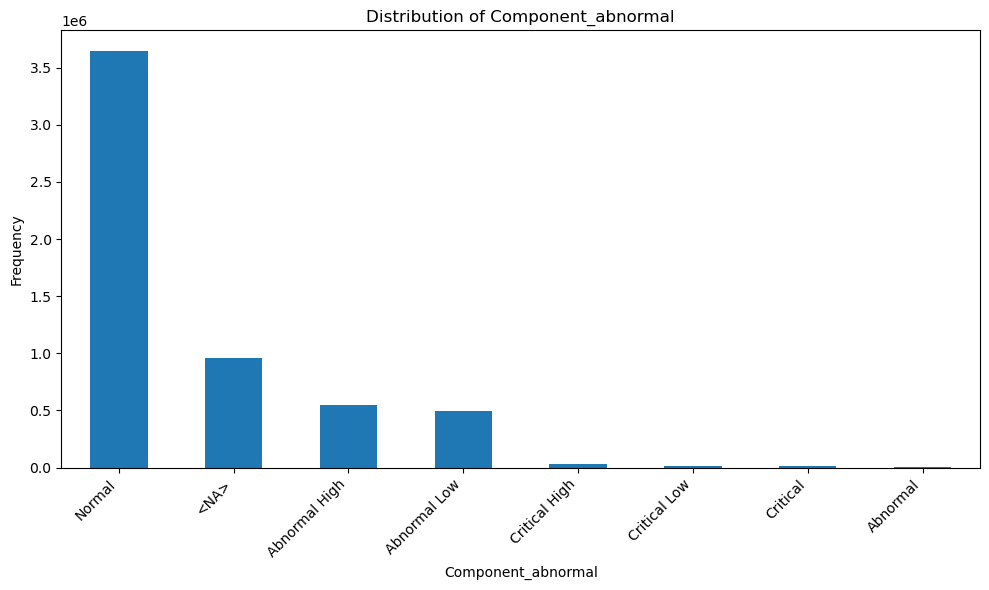

In [ ]:
stats = print_stats_and_graphs(labs, 'Component_abnormal', bins=100, save_plot=True)
stats = stats['value_counts']

In [116]:
total = stats['Normal'] + stats['Abnormal High'] + stats['Abnormal Low'] + stats['Critical High'] + stats['Critical Low']
print(f"Total number of labs: {total}")
print("Fraction of each category:")
print(f"Normal: {stats['Normal'] / total}")
print(f"Abnormal: {(stats['Abnormal High'] + stats['Abnormal Low']) / total}")
print(f"Critical: {(stats['Critical High'] + stats['Critical Low']) / total}")

Total number of labs: 4734332
Fraction of each category:
Normal: 0.769936920351171
Abnormal: 0.22029654870000667
Critical: 0.009766530948822348


## Vitals
Key insight: Q1-Q3 range of unique times is 28-171 (median: 97), which is much more useful. HR and SP02 taken every minute; other vitals atmost once on average, but for ~5% of patients they are taken much more frequently (177 times during admission). 

In [ ]:
vitals = dd.read_csv(mc_med_path + 'numerics.csv', assume_missing=True)
# Preprocess: Convert CSN to int
vitals['CSN'] = vitals['CSN'].astype('Int64')

In [5]:
unique_times = vitals.groupby('CSN')['Time'].nunique().compute()

# Report: Median number of unique Time per CSN
print(f"Median number of unique Time per CSN: {unique_times.median()}")
# Report: Q1 number of unique Time per CSN
print(f"Q1 number of unique Time per CSN: {unique_times.quantile(0.25)}")
# Report: Q3 number of unique Time per CSN 
print(f"Q3 number of unique Time per CSN: {unique_times.quantile(0.75)}")

Median number of unique Time per CSN: 97.0
Q1 number of unique Time per CSN: 28.0
Q3 number of unique Time per CSN: 171.0


Analyzing column 'Measure':
  Detected as Categorical Column

  Value Counts:
Measure
HR          7781180
SpO2        3694351
5min_HRV      57085
Pain          47959
SBP           31347
RR            28965
Perf          18263
Temp           3096
1min_HRV       2852
LPM_O2          466
Name: count, dtype: int64[pyarrow]

  Mode: ['HR']
Plot saved to plots/Measure_plot.png


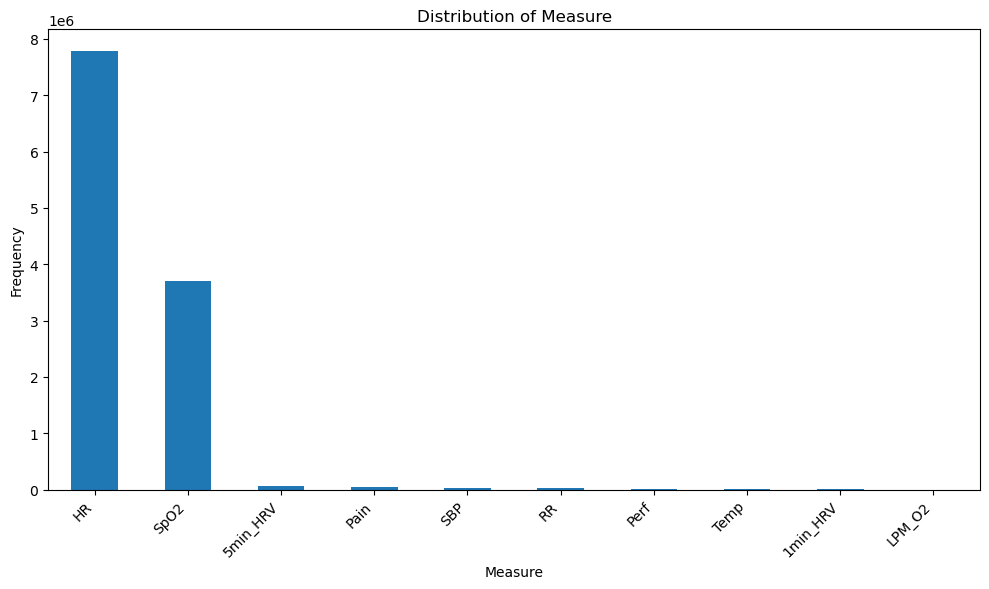

In [6]:
stats = print_stats_and_graphs(vitals, 'Measure', bins=100, save_plot=True)

In [ ]:
# For patients with atleast one RR measurement, calculate the median occurrences of RR

# first, filter out the patients without RR measurements
vitals_rr = vitals[vitals['Measure'] == 'RR']
# group by CSN and count the number of occurrences
vitals_rr_grouped = vitals_rr.groupby('CSN').size().compute()
vitals_rr_grouped.describe()

Median number of RR measurements per CSN: 1.0
Q1 number of RR measurements per CSN: 1.0
Q3 number of RR measurements per CSN: 2.0
Minimum number of RR measurements per CSN: 1
Maximum number of RR measurements per CSN: 306


In [ ]:
# Report: 99th percentile number of RR measurements per CSN
print(f"99th percentile RR measurements per CSN: {vitals_rr_grouped_computed.quantile(0.95)}")

99th percentil RR measurements per CSN: 177.39999999999986


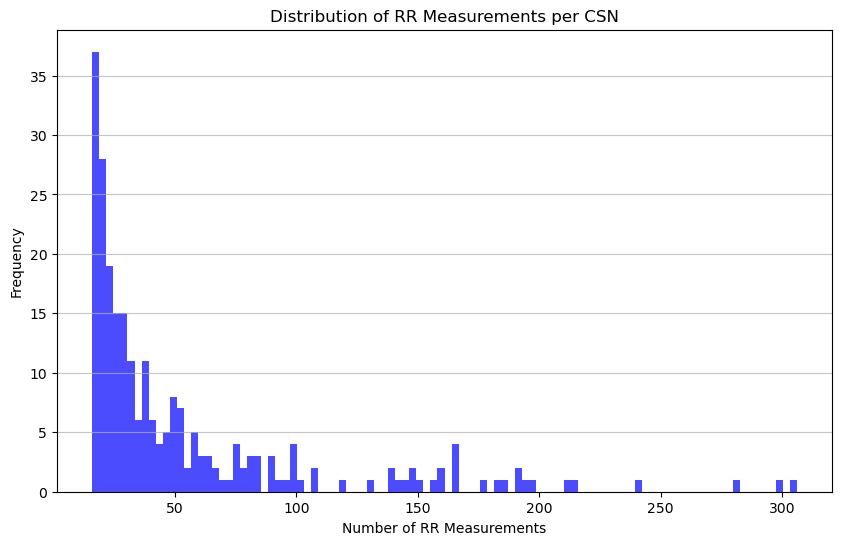

In [15]:
# plot the distribution of RR measurements
plt.figure(figsize=(10, 6))
# remove rr below 0
vitals_rr_grouped_computed = vitals_rr_grouped_computed[vitals_rr_grouped_computed > 5]
plt.hist(vitals_rr_grouped_computed, bins=100, color='blue', alpha=0.7)
plt.title('Distribution of RR Measurements per CSN')
plt.xlabel('Number of RR Measurements')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.savefig('rr_measurements_distribution.png')
plt.show()

## Meds
2-8 medicines per patient, with a median of 4. Seems like only one event is recorded per medication (reason for taking it, etc.).

In [4]:
meds = dd.read_csv(mc_med_path + 'meds.csv', assume_missing=True, dtype={'Active': 'object'})
# Preprocess: Convert MRN to int
meds['MRN'] = meds['MRN'].astype('Int64')

In [22]:
# Report: number of unique medicines per MRN
unique_meds = meds.groupby('MRN')['Med_ID'].nunique().compute()
unique_meds.describe()

count    33898.000000
mean         5.912207
std          5.663486
min          1.000000
25%          2.000000
50%          4.000000
75%          8.000000
max         68.000000
Name: Med_ID, dtype: float64

In [5]:
# Report: Number of unique medication events per MRN (use .size())
unique_meds_events = meds.groupby('MRN').size().compute()
unique_meds_events.describe()

count    33898.000000
mean         6.953744
std          8.107429
min          1.000000
25%          2.000000
50%          4.000000
75%          9.000000
max        140.000000
dtype: float64

## Prior Medical History
Majority of patients have a recorded medical history (65K out of 75K). 

In [7]:
pmh = dd.read_csv(mc_med_path + 'pmh.csv', assume_missing=True)
# Preprocess: Convert MRN to int
pmh['MRN'] = pmh['MRN'].astype('Int64')

In [ ]:
print("Number of unique MRNs in PMH: ", pmh['MRN'].nunique().compute())

Number of unique MRNs in PMH:  65315


In [9]:
pmh.head()

,MRN,Noted_date,CodeType,Code,Desc10,CCS,DescCCS
0,98816154,2288-11-16T00:00:00Z,Dx10,M954,Acquired deformity of chest and rib,209.0,Other acquired deformities
1,98816154,2293-06-16T00:00:00Z,Dx10,F411,Generalized anxiety disorder,651.0,Anxiety disorders
2,98816154,2293-06-16T00:00:00Z,Dx10,F329,"Major depressive disorder, single episode, uns...",657.0,Mood disorders
3,98816163,2252-04-19T00:00:00Z,Dx10,R7989,Other specified abnormal findings of blood che...,258.0,Other screening for suspected conditions (not ...
4,98816163,2252-04-30T00:00:00Z,Dx10,C8590,"Non-Hodgkin lymphoma, unspecified, unspecified...",38.0,Non-Hodgkin`s lymphoma


## Orders
Key takeway: 

In [24]:
orders = dd.read_csv(mc_med_path + 'orders.csv', assume_missing=True, dtype={'First_admin_time': 'object'})
# Preprocess: Convert CSN to int
orders['CSN'] = orders['CSN'].astype('Int64')

In [25]:
order_types = print_stats_and_graphs(orders, 'Order_type', save_plot=True, categorical_threshold=60)
# Report: Number of unique order types
unique_order_types = orders['Order_type'].nunique().compute()
print(f"Number of unique order types: {unique_order_types}")
# Report: Median number of unique order types per CSN
median_order_types_per_csn = orders.groupby('CSN')['Order_type'].nunique().median_approximate().compute()
print(f"Median number of unique order types per CSN: {median_order_types_per_csn}")
# Report: Q1 number of unique order types per CSN
print(f"Q1 number of unique order types per CSN: {orders.groupby('CSN')['Order_type'].nunique().quantile(0.25).compute()}")
# Report: Q3 number of unique order types per CSN
print(f"Q3 number of unique order types per CSN: {orders.groupby('CSN')['Order_type'].nunique().quantile(0.75).compute()}")# 

Analyzing column 'Order_type':
  Detected as Categorical Column

  Value Counts:
Order_type
Lab                      875752
Medications              753773
Nursing                  587392
Imaging                  227266
Isolation                129016
Lab Panel                115044
ECG                       95809
Consult                   95769
Point of Care Testing     68357
Diet                      56307
Microbiology Culture      54408
Admission                 51419
Lab Only                  46685
Code Status               18550
Outpatient Referral       18528
REHAB                     16344
Respiratory Care          11105
Precaution                 9316
Procedures                 7501
ECHO                       7216
Name: count, dtype: int64[pyarrow]
... and 38 more categories. Showing top 20.
Error analyzing or plotting categorical column 'Order_type'. Error: 'str' object has no attribute 'tolist'
  No plot generated.
Number of unique order types: 58
Median number of unique orde

In [27]:
# Let's only get the medications
medications = orders[orders['Order_type'] == 'Medications']

In [28]:
# Let's convert the First_admin_time to datetime
medications['First_admin_time'] = dd.to_datetime(medications['First_admin_time'], errors='coerce')
# Drop rows with NaT in First_admin_time
medications = medications.dropna(subset=['First_admin_time'])
# For each CSN, drop duplicates where First_admin_time is the same
medications = medications.drop_duplicates(subset=['CSN', 'First_admin_time'])

In [29]:
# Report: Number of unique First_admin_time per CSN
unique_first_admin_times = medications.groupby('CSN').size().compute()
unique_first_admin_times.describe()

count    59016.000000
mean         4.367172
std          4.000654
min          1.000000
25%          2.000000
50%          3.000000
75%          6.000000
max         45.000000
dtype: float64

## TODO
Correlation between vital frequency & outcome
Correlation between lab frequency & outcome
Correlation between lab frequency & vital frequency